# EDA

### 1. Chuẩn bị dữ liệu

In [1]:
# Load libraries
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch
import pandas as pd
import seaborn as sns
import os, re, glob

import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 120, "axes.titlesize": 13})



In [2]:
df_raw = pd.read_excel(r"C:\NguyenHoangThanhTam\data\clean\Chuan_hoa_Toan_Tinh.xlsx", dtype=str)
print(f"Đọc xong: {df_raw.shape[0]:,} bản ghi · {df_raw.shape[1]} cột")

Đọc xong: 101,355 bản ghi · 18 cột


In [12]:
YEAR_NOW = 2026
CLR = {"ngheo": "#C82333", "can": "#F8E71C"}

def parse_year(s):
    if pd.isna(s): return np.nan
    s = str(s).strip()
    m = re.match(r"^(\d{1,2})-(\d{1,2})-(\d{4})$", s)
    if m: return int(m.group(3))
    return np.nan

df = df_raw.copy()
df["NAM_SINH"] = df["NGAY_SINH"].apply(parse_year)
df["TUOI"]     = YEAR_NOW - df["NAM_SINH"]
df.loc[(df["TUOI"] < 0) | (df["TUOI"] > 110), "TUOI"] = np.nan
df.loc[(df["NAM_SINH"] < 1914) | (df["NAM_SINH"] > YEAR_NOW), "NAM_SINH"] = np.nan

df = df[df["PHAN_LOAI_HO"].isin(["Hộ nghèo", "Hộ cận nghèo"])].copy()
df["NHAN_KHAU"] = df.groupby("STT_HO")["STT_HO"].transform("count")
df["NHAN_KHAU"] = np.where(df["QUANHE_CHUHO"] == "Chủ hộ", df["NHAN_KHAU"], "")

print(f"Sau lọc 2 nhãn: {len(df):,} bản ghi")
print(f"Cột mới: NAM_SINH, TUOI, NHAN_KHAU")
df[["HO_TEN_THANH_VIEN","NGAY_SINH","NAM_SINH","TUOI","PHAN_LOAI_HO","DAN_TOC","HUYEN","NHAN_KHAU"]].head(6)


Sau lọc 2 nhãn: 98,478 bản ghi
Cột mới: NAM_SINH, TUOI, NHAN_KHAU


,HO_TEN_THANH_VIEN,NGAY_SINH,NAM_SINH,TUOI,PHAN_LOAI_HO,DAN_TOC,HUYEN,NHAN_KHAU
0,TRƯƠNG THỊ LÙN,01-01-1939,1939.0,87.0,Hộ nghèo,Kinh,Huyện Cư Jút,1
1,HOÀNG VĂN TRƯỜNG,27-06-1980,1980.0,46.0,Hộ nghèo,Kinh,Huyện Cư Jút,4
2,PHẠM THỊ SOI,10-11-1981,1981.0,45.0,Hộ nghèo,Kinh,Huyện Cư Jút,
3,HOÀNG THỊ BẢO THI,09-12-2011,2011.0,15.0,Hộ nghèo,Kinh,Huyện Cư Jút,
4,HOÀNG KỲ ANH,27-12-2013,2013.0,13.0,Hộ nghèo,Kinh,Huyện Cư Jút,
5,TRẦN VĂN LONG,10-03-1960,1960.0,66.0,Hộ nghèo,Kinh,Huyện Cư Jút,2


### 2. Phân tích mô tả

#### 2.1. Cơ cấu Độ tuổi Thô & Phân tầng Địa lý

**Mục tiêu**: Định hình tháp dân số thô và xác định địa bàn nào đang gánh gánh nặng nhân khẩu học lớn nhất tỉnh Đắk Nông.
- Đặc trưng phân phối năm sinh thô trích xuất từ trường NGAY_SINH toàn tỉnh biến thiên và phân bổ hình học thế nào? (Histogram / Density Plot)
- Quy mô đối tượng rà soát nghèo/cận nghèo phân bố cụ thể ra sao qua 8 huyện/thành phố và địa bàn nào đang gánh quy mô lớn nhất (>32 ngàn bản ghi)? (Bar Chart - Sắp xếp giảm dần)

#### Phân phối năm sinh thô trích xuất từ trường NGAY_SINH toàn tỉnh biến thiên và phân bổ hình học thế nào? 

In [8]:
# ── Giá trị ──
ns = df["NAM_SINH"].dropna()
for loai in ["Hộ nghèo", "Hộ cận nghèo"]:
    sub = df[df["PHAN_LOAI_HO"]==loai]["NAM_SINH"].dropna()
    print(f"{loai}: n={len(sub):,}  TB={sub.mean():.1f}  Median={sub.median():.0f}  "
          f"SD={sub.std():.1f}  [{sub.min():.0f}-{sub.max():.0f}]")


Hộ nghèo: n=52,004  TB=1997.7  Median=2003  SD=18.9  [1914-2023]
Hộ cận nghèo: n=44,595  TB=1995.8  Median=1999  SD=18.7  [1916-2022]


**Nhận xét:**
- Kết quả thống kê cho thấy dữ liệu gồm 52.004 nhân khẩu thuộc hộ nghèo và 44.595 nhân khẩu thuộc hộ cận nghèo có thông tin năm sinh hợp lệ. Nhân khẩu hộ nghèo có năm sinh trung bình là 1997,7 và trung vị là 2003, trong khi hộ cận nghèo có năm sinh trung bình là 1995,8 và trung vị là 1999. Điều này cho thấy cơ cấu nhân khẩu của hộ nghèo có xu hướng trẻ hơn hộ cận nghèo. Độ lệch chuẩn của hai nhóm tương đối tương đồng (khoảng 19 năm), phản ánh sự đa dạng về độ tuổi giữa các nhân khẩu trong mỗi nhóm hộ. Phạm vi năm sinh trải dài từ khoảng năm 1914–1916 đến 2022–2023, cho thấy dữ liệu bao gồm nhiều thế hệ khác nhau.

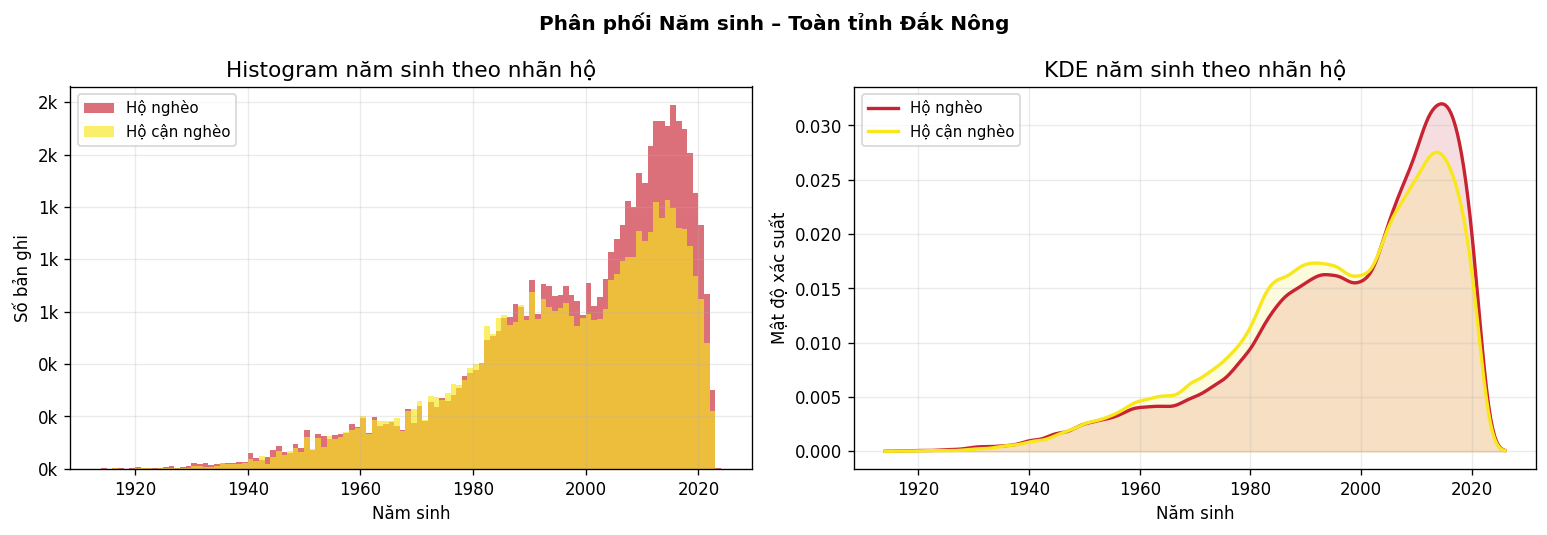

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fig.suptitle("Phân phối Năm sinh – Toàn tỉnh Đắk Nông", fontweight="bold")

# Histogram
ax = axes[0]
for label, c in [("Hộ nghèo", CLR["ngheo"]), ("Hộ cận nghèo", CLR["can"])]:
    vals = df[df["PHAN_LOAI_HO"]==label]["NAM_SINH"].dropna()
    ax.hist(vals, bins=range(int(ns.min()), int(ns.max())+2),
            alpha=0.65, color=c, label=label, edgecolor="none")
ax.set_xlabel("Năm sinh"); ax.set_ylabel("Số bản ghi")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x/1000:.0f}k"))
ax.legend(fontsize=9); ax.grid(alpha=0.25)
ax.set_title("Histogram năm sinh theo nhãn hộ")

# KDE
ax2 = axes[1]
for label, c in [("Hộ nghèo", CLR["ngheo"]), ("Hộ cận nghèo", CLR["can"])]:
    vals = df[df["PHAN_LOAI_HO"]==label]["NAM_SINH"].dropna()
    kde  = gaussian_kde(vals, bw_method=0.08)
    x    = np.linspace(1914, YEAR_NOW, 300)
    ax2.plot(x, kde(x), color=c, lw=2, label=label)
    ax2.fill_between(x, kde(x), alpha=0.15, color=c)
ax2.set_xlabel("Năm sinh"); ax2.set_ylabel("Mật độ xác suất")
ax2.legend(fontsize=9); ax2.grid(alpha=0.25)
ax2.set_title("KDE năm sinh theo nhãn hộ")

plt.tight_layout(); plt.show()


**Lưu ý về đơn vị phân tích:** Biểu đồ này đang ở cấp **nhân khẩu** (mỗi dòng là một thành viên), không phải cấp hộ. Vì vậy các diễn giải dưới đây mô tả cơ cấu tuổi của nhân khẩu thuộc từng nhóm hộ, chưa kết luận trực tiếp về đặc điểm trung bình của mỗi hộ.

**Nhận xét:**
- Histogram cho thấy phân phối năm sinh lệch trái, phần lớn nhân khẩu tập trung ở giai đoạn 1980-2020, phản ánh cơ cấu dân số tương đối trẻ trong nhóm hộ nghèo và hộ cận nghèo.
- Đường KDE xuất hiện hai đỉnh rõ rệt: đỉnh thứ nhất khoảng 1985-1995 (nhóm cha mẹ trong độ tuổi lao động) và đỉnh thứ hai khoảng 2010-2018 (nhóm trẻ em/phụ thuộc).
- Phân bố của nhân khẩu thuộc hộ nghèo có xu hướng dịch nhẹ về phía các năm sinh gần đây hơn so với hộ cận nghèo, gợi ý nhóm hộ nghèo có cơ cấu nhân khẩu trẻ hơn.

**Insight:**
- Dữ liệu gợi ý rằng nhân khẩu thuộc hộ nghèo có tỷ trọng trẻ em và thanh thiếu niên cao hơn, có thể liên quan đến gánh nặng phụ thuộc trong hộ.
- Sự xuất hiện mạnh của nhóm sinh 2010-2020 ở cả hai nhóm hộ gợi ý cần quan tâm đến giáo dục, y tế và an sinh trẻ em để hạn chế nguy cơ nghèo kéo dài qua các thế hệ. Đây là giả thuyết chính sách, chưa phải kết luận nhân quả.
- Nhóm sinh 1980-1995 là lực lượng lao động chính trong các hộ nghèo và cận nghèo; hiệu quả tạo việc làm cho nhóm này có thể liên quan đến kết quả giảm nghèo.
- Chênh lệch phân bố giữa hộ nghèo và hộ cận nghèo không quá lớn, cho thấy nhiều hộ cận nghèo vẫn có khả năng dễ tổn thương khi gặp cú sốc thu nhập hoặc việc làm.

**Hành động:**
- Ưu tiên các chính sách hỗ trợ trẻ em thuộc hộ nghèo như học bổng, bảo hiểm y tế và hỗ trợ học tập nhằm giảm nguy cơ nghèo kéo dài.
- Tăng cường đào tạo nghề và tạo việc làm ổn định cho nhóm lao động sinh giai đoạn 1980-1995.
- Khi cần kết luận ở cấp hộ, nên dùng các biến đã tổng hợp như `NHAN_KHAU`, `SO_HOC_DUONG`, `TY_LE_HOC_DUONG`, `SO_PHU_THUOC` thay vì chỉ dựa vào biểu đồ nhân khẩu.


#### Quy mô đối tượng rà soát phân bố ra sao qua 8 huyện/thành phố? 

In [10]:
huyen_cnt = (df.groupby(["HUYEN", "PHAN_LOAI_HO"]).size().unstack(fill_value=0)
                .assign(TONG=lambda x: x.sum(axis=1))
                .sort_values("TONG", ascending=False))
huyen_cnt["% Nghèo"] = (huyen_cnt["Hộ nghèo"] / huyen_cnt["TONG"] * 100).round(1)
huyen_cnt["% Cận nghèo"] = (huyen_cnt["Hộ cận nghèo"] / huyen_cnt["TONG"] * 100).round(1)

print("Quy mô bản ghi theo Huyện/TP:")
print(huyen_cnt[["Hộ nghèo","Hộ cận nghèo","TONG","% Nghèo","% Cận nghèo"]].to_string())
print(f"\nHuyện lớn nhất: {huyen_cnt['TONG'].idxmax()} ({huyen_cnt['TONG'].max():,})")
print(f"Huyện nhỏ nhất: {huyen_cnt['TONG'].idxmin()} ({huyen_cnt['TONG'].min():,})")

Quy mô bản ghi theo Huyện/TP:
PHAN_LOAI_HO         Hộ nghèo  Hộ cận nghèo   TONG  % Nghèo  % Cận nghèo
HUYEN                                                                   
Huyện Đắk Glong         24214          8694  32908     73.6         26.4
Huyện Tuy Đức           12519          9542  22061     56.7         43.3
Huyện Krông Nô           3758         11080  14838     25.3         74.7
Huyện Cư Jút             5525          6242  11767     47.0         53.0
Huyện Đắk Song           2998          5983   8981     33.4         66.6
Huyện Đắk R'lấp          2094          2134   4228     49.5         50.5
Huyện Đắk Mil            1093          1645   2738     39.9         60.1
Thành phố Gia Nghĩa       455           502    957     47.5         52.5

Huyện lớn nhất: Huyện Đắk Glong (32,908)
Huyện nhỏ nhất: Thành phố Gia Nghĩa (957)


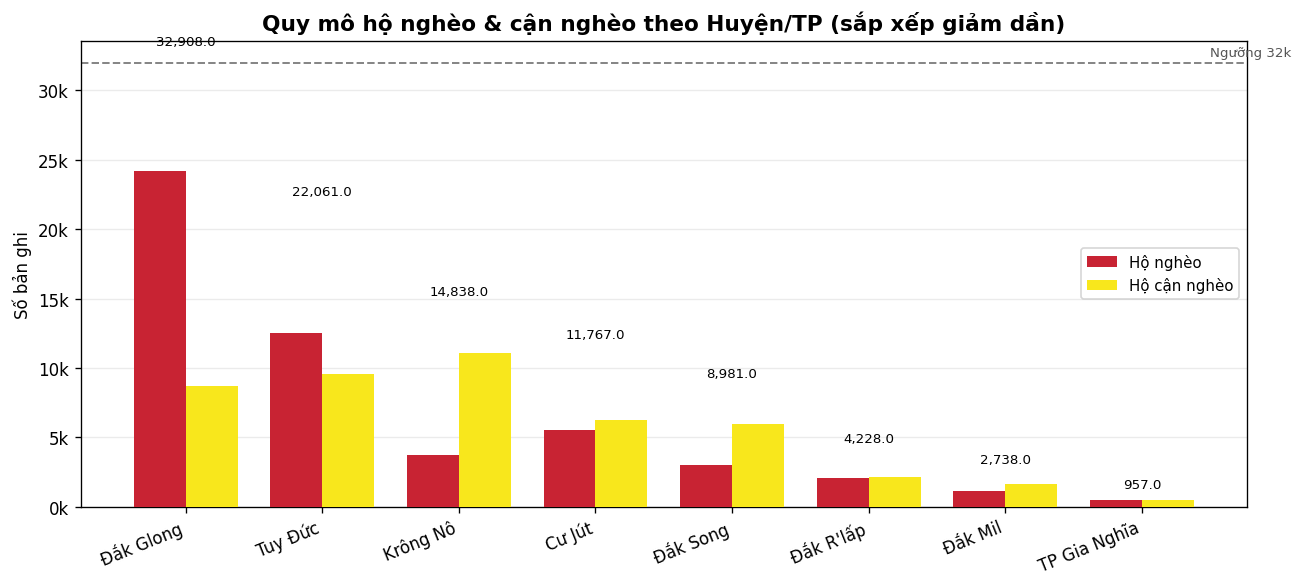

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
x, w = np.arange(len(huyen_cnt)), 0.38
ax.bar(x - w/2, huyen_cnt["Hộ nghèo"],     width=w, color=CLR["ngheo"], label="Hộ nghèo",   zorder=3)
ax.bar(x + w/2, huyen_cnt["Hộ cận nghèo"], width=w, color=CLR["can"],   label="Hộ cận nghèo", zorder=3)
ax.axhline(32000, color="#555", lw=1.2, ls="--", alpha=0.7)
ax.text(len(huyen_cnt)-0.5, 32500, "Ngưỡng 32k", fontsize=8, color="#555")
for xi, (_, row) in zip(x, huyen_cnt.iterrows()):
    ax.text(xi, row["TONG"]+400, f"{row['TONG']:,}", ha="center", fontsize=8, fontweight="500")
ax.set_xticks(x)
ax.set_xticklabels([h.replace("Huyện ","").replace("Thành phố ","TP ") for h in huyen_cnt.index],
                   rotation=22, ha="right")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x/1000:.0f}k"))
ax.set_ylabel("Số bản ghi"); ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.25, zorder=0)
ax.set_title("Quy mô hộ nghèo & cận nghèo theo Huyện/TP (sắp xếp giảm dần)", fontweight="bold")
plt.tight_layout(); plt.show()


**Nhận xét:**
- Quy mô đối tượng rà soát nghèo và cận nghèo phân bố không đồng đều giữa các huyện/thành phố của tỉnh Đắk Nông.
- Đắk Glong có số lượng bản ghi thuộc hộ nghèo cao nhất toàn tỉnh (> 32 nghìn bản ghi), vượt xa các địa phương còn lại và chiếm tỷ trọng lớn trong tổng số đối tượng rà soát.
- Tuy Đức đứng thứ hai về quy mô nhóm nghèo, trong khi Krông Nô và Đắk Song nổi bật với số lượng bản ghi thuộc hộ cận nghèo cao hơn đáng kể so với hộ nghèo.
- TP Gia Nghĩa có quy mô bản ghi nghèo/cận nghèo thấp nhất trong tập dữ liệu.
- Nhóm huyện Krông Nô, Đắk Song, Cư Jút, Đắk Mil có số bản ghi cận nghèo lớn hơn số bản ghi nghèo, gợi ý đây là các địa bàn cần theo dõi nguy cơ tái nghèo.

**Insight:**
- Đắk Glong là địa bàn tập trung nhiều đối tượng rà soát nghèo nhất, nên kết quả giảm nghèo toàn tỉnh có thể phụ thuộc đáng kể vào thay đổi tại địa bàn này.
- Các huyện có quy mô cận nghèo cao như Krông Nô và Đắk Song cần được theo dõi vì nhóm cận nghèo có thể dễ tổn thương trước cú sốc về việc làm, thu nhập hoặc thiên tai.
- Chênh lệch lớn giữa các địa phương cho thấy tình trạng nghèo/cận nghèo có tính tập trung theo địa bàn; để giải thích nguyên nhân cần bổ sung thêm biến về sinh kế, hạ tầng, dân tộc, tiếp cận dịch vụ và chính sách.
- Không nên diễn giải trực tiếp rằng địa phương có ít bản ghi nghèo hơn là có điều kiện kinh tế - xã hội tốt hơn nếu chưa có biến kiểm chứng.

**Hành động:**
- Ưu tiên theo dõi và phân tích sâu Đắk Glong và Tuy Đức do quy mô đối tượng nghèo lớn.
- Xây dựng chương trình phòng chống tái nghèo tại Krông Nô, Đắk Song, Cư Jút và Đắk Mil, nơi nhóm cận nghèo chiếm tỷ trọng cao.
- Thiết lập cơ chế giám sát định kỳ đối với các hộ cận nghèo để phát hiện sớm nguy cơ quay lại diện nghèo.


#### 2.2. Cơ cấu Phân loại Hộ & Đặc thù Dân tộc
**Mục tiêu:** Đánh giá thực trạng phân hóa đói nghèo tĩnh và độ tổn thương sâu của các thành phần tộc người.
- Tỷ lệ phân hóa nhị phân giữa nhóm nghèo sâu và nhóm mấp mé tổn thương là bao nhiêu? (Donut Chart)
- Cơ cấu đói nghèo có sự khác biệt rõ rệt giữa các dân tộc không? (Stacked Bar Chart)

#### Tỷ lệ phân hóa giữa Hộ nghèo và Hộ cận nghèo toàn tỉnh? 

In [12]:
# ── Giá trị ──
loai_cnt = df["PHAN_LOAI_HO"].value_counts()
total    = loai_cnt.sum()

for loai, cnt in loai_cnt.items():
    print(f"  {loai:<22}: {cnt:>8,}  ({cnt/total*100:.2f}%)")
print(f"  {'Tổng':<22}: {total:>8,}")
print(f"  Tỉ lệ Nghèo/Cận nghèo: {loai_cnt['Hộ nghèo']/loai_cnt['Hộ cận nghèo']:.3f}")


  Hộ nghèo              :   52,656  (53.47%)
  Hộ cận nghèo          :   45,822  (46.53%)
  Tổng                  :   98,478
  Tỉ lệ Nghèo/Cận nghèo: 1.149


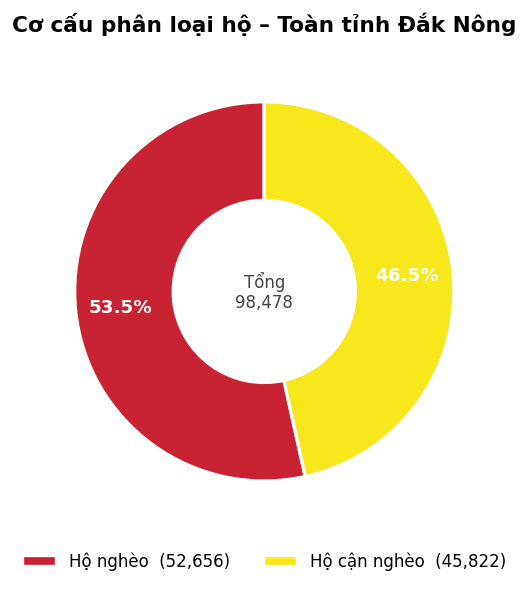

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
wedges, _, autotexts = ax.pie(
    loai_cnt, labels=None,
    colors=[CLR["ngheo"], CLR["can"]],
    autopct="%1.1f%%", startangle=90,
    wedgeprops={"width": 0.52, "edgecolor": "white", "linewidth": 2},
    pctdistance=0.76, textprops={"fontsize": 11}
)
for at in autotexts:
    at.set_fontweight("bold"); at.set_color("white")
ax.legend(wedges, [f"{l}  ({v:,})" for l, v in loai_cnt.items()],
          loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=10, frameon=False)
ax.text(0, 0, f"Tổng\n{total:,}", ha="center", va="center", fontsize=10,
        color="#444", fontweight="500")
ax.set_title("Cơ cấu phân loại hộ – Toàn tỉnh Đắk Nông", fontweight="bold", pad=14)
plt.tight_layout(); plt.show()


**Nhận xét:**
- **Hộ nghèo chiếm khoảng 53.5%**, hộ cận nghèo khoảng 46.5%; nhóm nghèo nhỉnh hơn nhóm cận nghèo trong tập dữ liệu rà soát.
- Tỉ lệ xấp xỉ 1.15:1 (nghèo/cận nghèo) cho thấy quy mô hai nhóm khá cân bằng, phù hợp cho các phân tích so sánh nghèo/cận nghèo.

**Insight:**
- Nhóm cận nghèo chiếm tỷ trọng lớn, đóng vai trò như vùng đệm dễ tổn thương nếu xuất hiện cú sốc về thu nhập, bệnh tật, thiên tai hoặc việc làm.
- Chỉ từ một lát cắt dữ liệu hiện tại chưa thể kết luận chiến lược giảm nghèo hiệu quả hay không; cần dữ liệu nhiều năm để đánh giá xu hướng.

**Hành động:**
- Theo dõi tỉ lệ nghèo/cận nghèo theo thời gian để đánh giá hiệu quả chính sách.
- Xây dựng mạng lưới bảo trợ xã hội và cảnh báo sớm cho nhóm cận nghèo để phòng ngừa tái nghèo.


#### Cơ cấu nghèo có sự khác biệt rõ rệt giữa các dân tộc không?

In [14]:
# ── Giá trị ──
TOP_N = 10
top_dt = df["DAN_TOC"].value_counts().head(TOP_N).index.tolist()
dt_df  = (df[df["DAN_TOC"].isin(top_dt)]
          .groupby(["DAN_TOC","PHAN_LOAI_HO"]).size().unstack(fill_value=0))
dt_pct = dt_df.div(dt_df.sum(axis=1), axis=0) * 100
dt_pct = dt_pct.sort_values("Hộ nghèo", ascending=False)
dt_abs = dt_df.loc[dt_pct.index]
dt_abs["Tổng"] = dt_abs.sum(axis=1)
dt_show = pd.concat([dt_abs, dt_pct.rename(columns={
    "Hộ nghèo":"% Nghèo","Hộ cận nghèo":"% Cận nghèo"})
    [["% Nghèo","% Cận nghèo"]].round(1)], axis=1)

print("Cơ cấu nghèo theo Dân tộc (Top 10 – sắp xếp theo % Nghèo giảm dần):")
print(dt_show.to_string())
top_ngheo_dt = dt_pct["Hộ nghèo"].idxmax()
print(f"\nDân tộc có tỉ lệ Hộ nghèo cao nhất: {top_ngheo_dt} ({dt_pct.loc[top_ngheo_dt,'Hộ nghèo']:.1f}%)")


Cơ cấu nghèo theo Dân tộc (Top 10 – sắp xếp theo % Nghèo giảm dần):
PHAN_LOAI_HO  Hộ cận nghèo  Hộ nghèo   Tổng  % Nghèo  % Cận nghèo
DAN_TOC                                                          
Dao                   4224     19273  23497     82.0         18.0
H'Mông                2171      2218   4389     50.5         49.5
Ê-đê                  2325      2281   4606     49.5         50.5
M'Nông               10196      9471  19667     48.2         51.8
Tày                   2062      1881   3943     47.7         52.3
Kinh                 15044     11041  26085     42.3         57.7
Khác                  4444      2759   7203     38.3         61.7
Thái                   877       525   1402     37.4         62.6
Sán Chay              1137       620   1757     35.3         64.7
Gia-rai               2111      1134   3245     34.9         65.1

Dân tộc có tỉ lệ Hộ nghèo cao nhất: Dao (82.0%)


In [15]:
print(dt_pct.head())
print(dt_pct.columns.tolist())

PHAN_LOAI_HO  Hộ cận nghèo   Hộ nghèo
DAN_TOC                              
Dao              17.976763  82.023237
H'Mông           49.464571  50.535429
Ê-đê             50.477638  49.522362
M'Nông           51.843189  48.156811
Tày              52.295207  47.704793
['Hộ cận nghèo', 'Hộ nghèo']


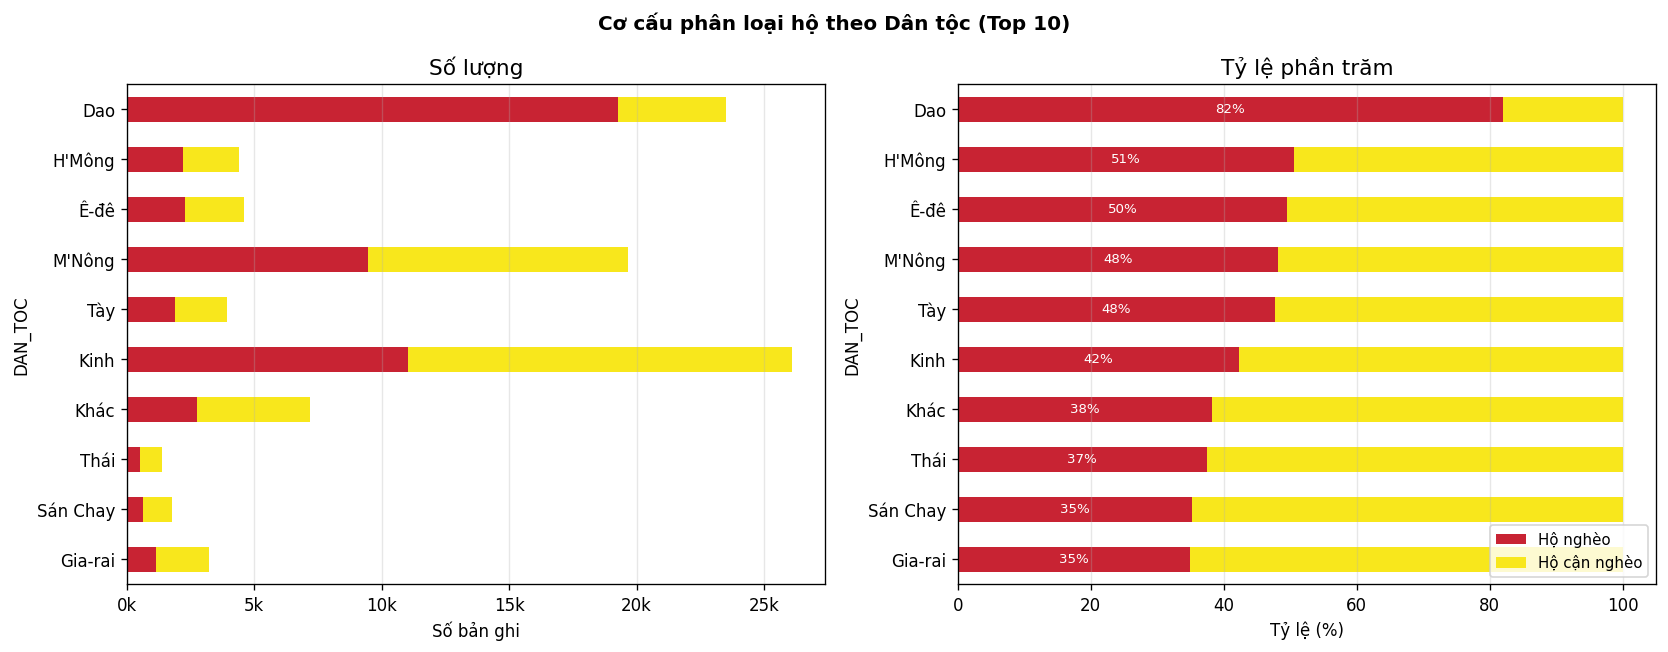

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle("Cơ cấu phân loại hộ theo Dân tộc (Top 10)", fontweight="bold")

dt_abs[["Hộ nghèo","Hộ cận nghèo"]].loc[dt_pct.index[::-1]].plot(
    kind="barh", stacked=True,
    color=[CLR["ngheo"], CLR["can"]], ax=axes[0], legend=False)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x/1000:.0f}k"))
axes[0].set_xlabel("Số bản ghi"); axes[0].set_title("Số lượng")
axes[0].grid(axis="x", alpha=0.3)

dt_pct.loc[dt_pct.index[::-1], ["Hộ nghèo", "Hộ cận nghèo"]].plot(
    kind="barh", stacked=True,
    color=[CLR["ngheo"], CLR["can"]], ax=axes[1])
for i, dt in enumerate(dt_pct.index[::-1]):
    pct_n = dt_pct.loc[dt, "Hộ nghèo"]
    axes[1].text(pct_n/2, i, f"{pct_n:.0f}%", ha="center", va="center",
                 fontsize=8, color="white", fontweight="500")
axes[1].set_xlabel("Tỷ lệ (%)"); axes[1].set_title("Tỷ lệ phần trăm")
axes[1].legend(loc="lower right", fontsize=9)
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout(); plt.show()


**Nhận xét:**
- Dân tộc Kinh có số lượng hộ nghèo và cận nghèo lớn nhất về quy mô tuyệt đối, tiếp theo là Dao và M'Nông. Điều này phản ánh quy mô dân số/đối tượng rà soát lớn của các nhóm này trong tỉnh.
- Xét theo tỷ lệ, dân tộc Dao có tỷ lệ hộ nghèo rất cao, vượt xa các dân tộc còn lại.
- Các dân tộc H'Mông, Ê-đê, M'Nông và Tày có tỷ lệ hộ nghèo dao động quanh mức gần một nửa số hộ thuộc diện nghèo.
- Dân tộc Kinh có tỷ lệ hộ nghèo thấp hơn và tỷ lệ hộ cận nghèo cao hơn so với nhiều nhóm dân tộc thiểu số.
- Các nhóm dân tộc có quy mô nhỏ cần được diễn giải thận trọng vì tỷ lệ phần trăm có thể dao động mạnh khi số quan sát thấp.

**Insight:**
- Tình trạng nghèo có sự khác biệt rõ giữa các nhóm dân tộc, cho thấy dân tộc là một đặc trưng quan trọng liên quan đến phân loại nghèo/cận nghèo tại Đắk Nông.
- Nhóm Dao là nhóm có tỷ lệ nghèo quan sát cao nhất, nên cần được ưu tiên phân tích sâu hơn theo địa bàn, sinh kế và quy mô hộ.
- Các khác biệt theo dân tộc có thể liên quan đến điều kiện địa bàn, sinh kế, giáo dục, việc làm, tiếp cận dịch vụ và chính sách; notebook hiện tại chưa có đủ biến để kết luận cơ chế nguyên nhân.
- Cần phân biệt giữa **quy mô nghèo** (số hộ nghèo tuyệt đối) và **mức độ nghèo** (tỷ lệ hộ nghèo trong từng nhóm) khi phân bổ nguồn lực.

**Hành động:**
- Ưu tiên phân tích sâu nhóm Dao và các nhóm dân tộc có tỷ lệ nghèo cao.
- Bổ sung hoặc kết nối thêm dữ liệu về sinh kế, học vấn, nghề nghiệp, hạ tầng và tiếp cận dịch vụ để giải thích vì sao tỷ lệ nghèo khác biệt giữa các nhóm.
- Theo dõi riêng các dân tộc có quy mô nhỏ nhưng tỷ lệ nghèo cao để tránh bỏ sót trong quá trình phân bổ nguồn lực.


### 2.3. Thực trạng Vai trò Chủ hộ & Trạng thái dữ liệu
**Mục tiêu:** Khảo sát độ tuổi của lực lượng trụ cột gia đình và chất lượng đồng bộ dữ liệu hành chính công.
- Độ tuổi trung bình của Chủ hộ tại Đắk Nông hiện nay là bao nhiêu? 
- Tỷ lệ hồ sơ đã được đồng bộ mã định danh thành công và phân phối theo trạng thái ra sao?

In [17]:
# ── Giá trị ──
chu_ho = df[df["QUANHE_CHUHO"] == "Chủ hộ"].dropna(subset=["TUOI"])
order_h = chu_ho.groupby("HUYEN")["TUOI"].median().sort_values(ascending=False).index.tolist()

print("Thống kê tuổi Chủ hộ theo Huyện & Phân loại hộ:")
stats = (chu_ho.groupby(["HUYEN","PHAN_LOAI_HO"])["TUOI"]
         .agg(N="count", Mean="mean", Median="median", Std="std",
              Q1=lambda x: x.quantile(0.25), Q3=lambda x: x.quantile(0.75))
         .round(1).unstack("PHAN_LOAI_HO"))
print(stats.to_string())
print()
for loai in ["Hộ nghèo","Hộ cận nghèo"]:
    sub = chu_ho[chu_ho["PHAN_LOAI_HO"]==loai]["TUOI"]
    print(f"  Toàn tỉnh – {loai}: TB={sub.mean():.1f}  Median={sub.median():.0f}  "
          f"SD={sub.std():.1f}  Range=[{sub.min():.0f}-{sub.max():.0f}]")



Thống kê tuổi Chủ hộ theo Huyện & Phân loại hộ:
                               N                  Mean                Median                   Std                    Q1                    Q3         
PHAN_LOAI_HO        Hộ cận nghèo Hộ nghèo Hộ cận nghèo Hộ nghèo Hộ cận nghèo Hộ nghèo Hộ cận nghèo Hộ nghèo Hộ cận nghèo Hộ nghèo Hộ cận nghèo Hộ nghèo
HUYEN                                                                                                                                                  
Huyện Cư Jút                1314     1162         51.2     51.9         48.0     49.0         13.9     14.7         40.0     40.0         61.0     63.0
Huyện Krông Nô              2253      703         48.0     47.5         45.0     44.0         13.9     13.9         38.0     37.0         56.0     54.0
Huyện Tuy Đức               2151     2451         46.6     48.7         44.0     45.0         13.3     14.3         37.0     38.0         54.0     57.0
Huyện Đắk Glong             1732     445

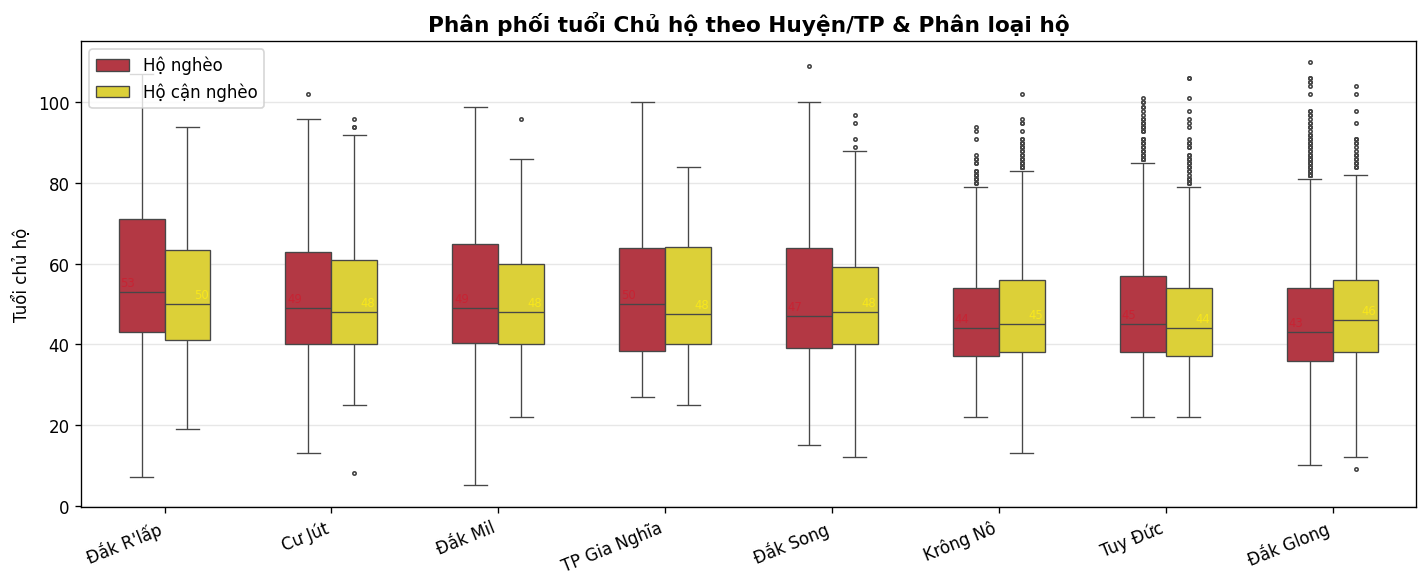

In [18]:
short = {h: h.replace("Huyện ","").replace("Thành phố ","TP ") for h in order_h}

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=chu_ho, x="HUYEN", y="TUOI", order=order_h,
                hue="PHAN_LOAI_HO", hue_order=["Hộ nghèo","Hộ cận nghèo"],
            palette=[CLR["ngheo"], CLR["can"]],
            width=0.55, linewidth=0.8, fliersize=2, ax=ax)
ax.set_xticklabels([short[h] for h in order_h], rotation=22, ha="right")
ax.set_xlabel(""); ax.set_ylabel("Tuổi chủ hộ")
ax.set_title("Phân phối tuổi Chủ hộ theo Huyện/TP & Phân loại hộ", fontweight="bold")
ax.legend(title="Phân loại", fontsize=9, title_fontsize=9)
ax.legend(title=None)
ax.grid(axis="y", alpha=0.3)
for xi, huyen in enumerate(order_h):
    for loai, off, c in [("Hộ nghèo",-0.22,CLR["ngheo"]),("Hộ cận nghèo",+0.22,CLR["can"])]:
        med = chu_ho[(chu_ho["HUYEN"]==huyen)&(chu_ho["PHAN_LOAI_HO"]==loai)]["TUOI"].median()
        if not np.isnan(med):
            ax.text(xi+off, med+1.5, f"{med:.0f}", ha="center", fontsize=7, color=c, fontweight="500")
plt.tight_layout(); plt.show()


**Nhận xét:**
- Tuổi chủ hộ tập trung chủ yếu trong khoảng 40-60 tuổi ở tất cả các huyện.
- Đắk R'lấp có chủ hộ lớn tuổi nhất theo trung vị, trong khi Đắk Glong có trung vị tuổi chủ hộ thấp hơn.
- Sự khác biệt tuổi chủ hộ giữa hộ nghèo và hộ cận nghèo trong cùng huyện khá nhỏ.

**Insight:**
- Tuổi chủ hộ không cho thấy khả năng phân biệt mạnh giữa hộ nghèo và hộ cận nghèo ở phân tích mô tả.
- Khác biệt nghèo/cận nghèo giữa các huyện có thể liên quan đến các yếu tố khác như dân tộc, sinh kế, việc làm và điều kiện địa bàn; cần kiểm tra bằng mô hình kiểm soát thay vì kết luận trực tiếp từ boxplot.
- Đắk R'lấp có xu hướng chủ hộ lớn tuổi hơn, còn Đắk Glong có cơ cấu chủ hộ trẻ hơn; đây là tín hiệu mô tả để định hướng phân tích tiếp theo.

**Hành động:**
- Xem xét chính sách an sinh/chăm sóc sức khỏe cho nhóm chủ hộ lớn tuổi tại các địa bàn có trung vị tuổi cao.
- Với các huyện có chủ hộ trẻ hơn, nên kiểm tra thêm biến việc làm, đào tạo nghề và quy mô phụ thuộc trong hộ.


In [23]:
print(kq_df)

                                Số bản ghi  Tỷ lệ (%)
KET_QUA                                              
Tìm thấy - CCCD                      61693      62.65
Không tìm thấy                       20159      20.47
Tìm thấy - Thông tin                 14257      14.48
Tìm thấy - CMND                       1692       1.72
Lỗi dữ liệu                            359       0.36
Chưa rà soát / Trạng thái khác         318       0.32


#### Tỷ lệ đồng bộ mã định danh thành công toàn tỉnh?

In [20]:
# ── Giá trị ──
kq_cnt = df["KET_QUA"].value_counts()
kq_df  = kq_cnt.rename("Số bản ghi").to_frame()
kq_df["Tỷ lệ (%)"] = (kq_df["Số bản ghi"] / len(df) * 100).round(2)
print("Phân phối trạng thái KET_QUA:")
print(kq_df.to_string())
found = kq_df[kq_df.index.str.contains("Tìm thấy")]["Số bản ghi"].sum()
print(f"\nTổng 'Tìm thấy' (thành công): {found:,} ({found/len(df)*100:.1f}%)")
print(f"Thất bại / Lỗi: {len(df)-found:,} ({(len(df)-found)/len(df)*100:.1f}%)")


Phân phối trạng thái KET_QUA:
                                Số bản ghi  Tỷ lệ (%)
KET_QUA                                              
Tìm thấy - CCCD                      61693      62.65
Không tìm thấy                       20159      20.47
Tìm thấy - Thông tin                 14257      14.48
Tìm thấy - CMND                       1692       1.72
Lỗi dữ liệu                            359       0.36
Chưa rà soát / Trạng thái khác         318       0.32

Tổng 'Tìm thấy' (thành công): 77,642 (78.8%)
Thất bại / Lỗi: 20,836 (21.2%)


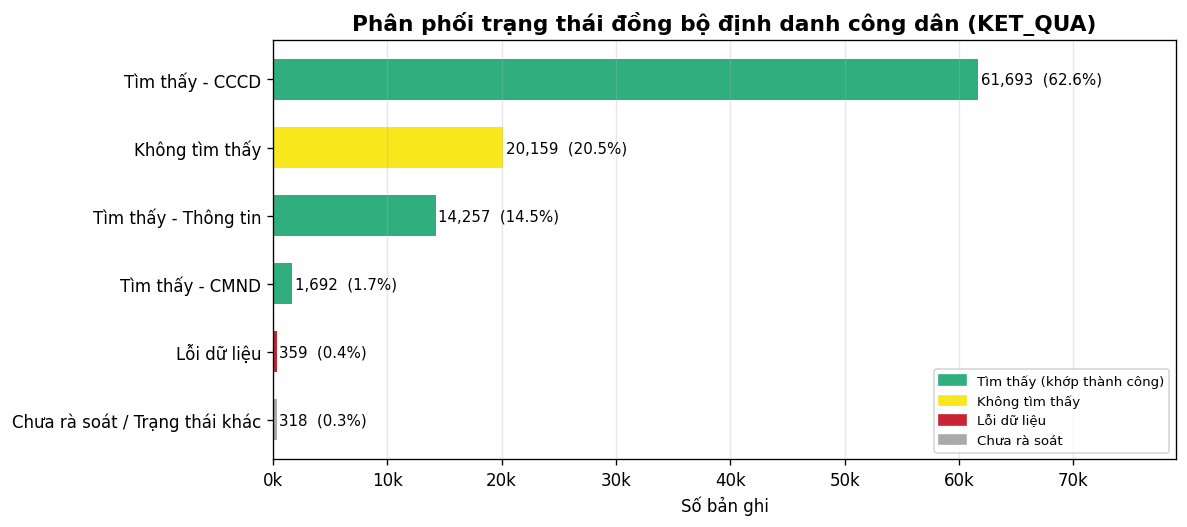

In [21]:
colors_kq = []
for k in kq_cnt.index:
    if "Tìm thấy" in k: colors_kq.append("#2EAF7D")
    elif "Lỗi"    in k: colors_kq.append(CLR["ngheo"])
    elif "Không"  in k: colors_kq.append(CLR["can"])
    else:               colors_kq.append("#AAAAAA")

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(kq_cnt.index[::-1], kq_cnt.values[::-1],
               color=colors_kq[::-1], height=0.6, edgecolor="none")
for bar, val in zip(bars, kq_cnt.values[::-1]):
    ax.text(bar.get_width()+200, bar.get_y()+bar.get_height()/2,
            f"{val:,}  ({val/len(df)*100:.1f}%)", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x/1000:.0f}k"))
ax.set_xlim(0, kq_cnt.max()*1.28)
ax.set_xlabel("Số bản ghi"); ax.grid(axis="x", alpha=0.3)
ax.set_title("Phân phối trạng thái đồng bộ định danh công dân (KET_QUA)", fontweight="bold")
legend_h = [Patch(color="#2EAF7D", label="Tìm thấy (khớp thành công)"),
            Patch(color=CLR["can"],   label="Không tìm thấy"),
            Patch(color=CLR["ngheo"], label="Lỗi dữ liệu"),
            Patch(color="#AAAAAA",    label="Chưa rà soát")]
ax.legend(handles=legend_h, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()


**Nhận xét:**
- Khoảng **78-80% hồ sơ** được khớp thành công, cho thấy mức độ đồng bộ dữ liệu tương đối tốt đối với dữ liệu hành chính địa phương.
- Khoảng **20% hồ sơ không tìm thấy** là nhóm cần rà soát thêm vì chưa xác minh được qua cơ sở dữ liệu hiện có.
- Tỷ lệ lỗi dữ liệu thấp nhưng vẫn cần xử lý riêng để tránh ảnh hưởng đến các bước phân tích/đối chiếu sau này.

**Insight:**
- Hồ sơ không khớp có thể đến từ nhiều nguyên nhân như CCCD chưa cập nhật, nhập sai thông tin, thay đổi giấy tờ hoặc thiếu dữ liệu định danh.
- Nhóm không xác minh được danh tính làm tăng nhu cầu rà soát thủ công trước khi sử dụng dữ liệu cho chi trả, hỗ trợ hoặc đánh giá chính sách.

**Hành động:**
- Ưu tiên rà soát thủ công nhóm hồ sơ “Không tìm thấy” theo huyện/xã.
- Đối chiếu với sổ hộ khẩu, CCCD/CMND và hồ sơ địa phương để bổ sung thông tin.
- Tách riêng nhóm lỗi dữ liệu để xử lý trước khi dùng cho phân tích định danh hoặc chính sách hỗ trợ.


## 3. Phân tích Khám phá (EDA)

### 3.1. Khám phá Vòng đời Đói nghèo
**Mục tiêu:** Phát hiện các mối liên hệ ẩn và quy luật phân hóa phi tuyến tính giữa tuổi tác với thực trạng nghèo đói.
- Có sự khác biệt hình học giữa đường cong phân phối tuổi của nhóm Hộ nghèo và Hộ cận nghèo không? 
- Trạng thái nghèo sâu có xu hướng lệch về hai đầu tháp tuổi không?

#### Đường cong phân phối tuổi thực tế của 2 nhóm hộ có sự khác biệt hình học nào?

In [34]:
# ── Giá trị ──
print("Phân vị tuổi thực tế theo nhãn hộ:")
kde_stats = (df.groupby("PHAN_LOAI_HO")["TUOI"]
             .describe(percentiles=[0.1,0.25,0.5,0.75,0.9]).round(1))
print(kde_stats.to_string())
print()
for loai in ["Hộ nghèo","Hộ cận nghèo"]:
    sub = df[df["PHAN_LOAI_HO"]==loai]["TUOI"].dropna()
    u50 = (sub >= 50).mean() * 100
    tre = (sub < 18).mean() * 100
    print(f"  {loai}: U50+ = {u50:.1f}%   <18 tuổi = {tre:.1f}%")


Phân vị tuổi thực tế theo nhãn hộ:
                count  mean   std  min  10%   25%   50%   75%   90%    max
PHAN_LOAI_HO                                                              
Hộ cận nghèo  44595.0  30.2  18.7  4.0  9.0  15.0  27.0  42.0  57.0  110.0
Hộ nghèo      52003.0  28.3  18.9  3.0  9.0  13.0  23.0  39.0  56.0  110.0

  Hộ nghèo: U50+ = 13.7%   <18 tuổi = 37.5%
  Hộ cận nghèo: U50+ = 15.7%   <18 tuổi = 32.1%


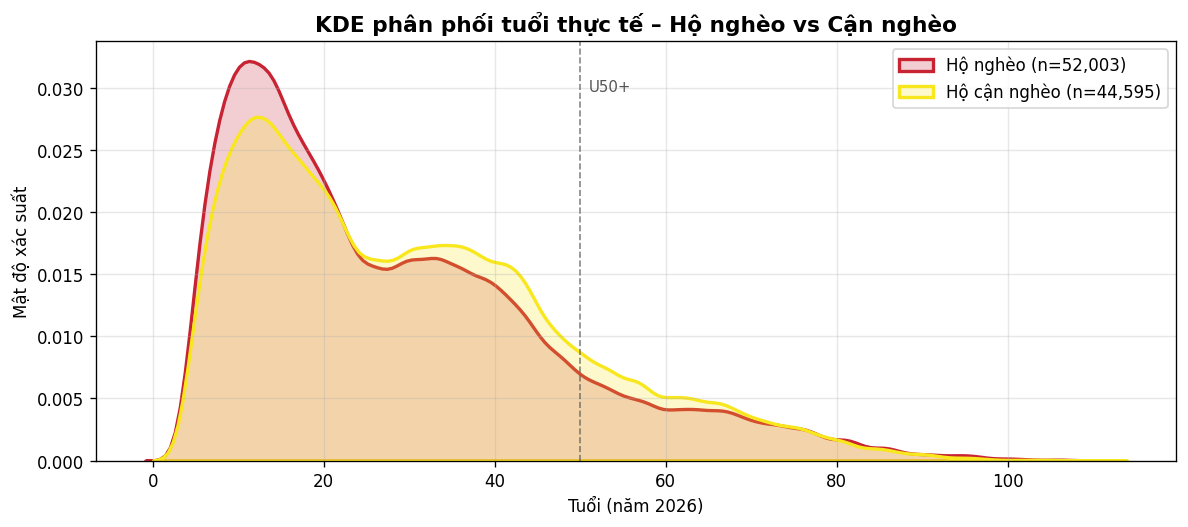

In [37]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for label, c in [("Hộ nghèo", CLR["ngheo"]), ("Hộ cận nghèo", CLR["can"])]:
    vals = df[df["PHAN_LOAI_HO"]==label]["TUOI"].dropna()
    sns.kdeplot(vals, ax=ax, color=c, fill=True, alpha=0.22, lw=2,
                label=f"{label} (n={len(vals):,})", bw_adjust=0.6)
ax.axvline(50, color="#555", lw=1, ls="--", alpha=0.7)
ax.text(51, ax.get_ylim()[1]*0.88, "U50+", fontsize=9, color="#555")
ax.set_xlabel("Tuổi (năm 2026)"); ax.set_ylabel("Mật độ xác suất")
ax.set_title("KDE phân phối tuổi thực tế – Hộ nghèo vs Cận nghèo", fontweight="bold")
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


**Lưu ý về đơn vị phân tích:** Biểu đồ KDE này ở cấp **nhân khẩu**, không phải cấp hộ. Các kết luận dưới đây mô tả phân phối tuổi của các cá nhân thuộc từng nhóm hộ.

**Nhận xét:**
- Cả hai nhóm hộ đều có đỉnh mật độ cao nhất ở độ tuổi 10-15 tuổi, cho thấy trẻ em và thanh thiếu niên chiếm tỷ trọng lớn trong cơ cấu nhân khẩu.
- Đỉnh KDE của nhóm nhân khẩu thuộc hộ nghèo cao hơn hộ cận nghèo, gợi ý sự tập trung dân số trẻ rõ hơn trong nhóm này.
- Trong khoảng 25-50 tuổi, đường KDE của nhân khẩu thuộc hộ cận nghèo nằm cao hơn tương đối ổn định, gợi ý tỷ trọng người trong độ tuổi lao động cao hơn.
- Sau mốc 50 tuổi, mật độ của cả hai nhóm giảm nhanh; khác biệt ở nhóm cao tuổi không phải điểm nổi bật nhất của biểu đồ.

**Insight:**
- Dữ liệu gợi ý rằng nhân khẩu thuộc hộ nghèo có xu hướng trẻ hơn và tập trung nhiều hơn ở nhóm trẻ em/thanh thiếu niên.
- Nhân khẩu thuộc hộ cận nghèo có tỷ trọng cao hơn ở nhóm tuổi lao động trưởng thành, điều này có thể liên quan đến khả năng tạo thu nhập tốt hơn, nhưng chưa đủ cơ sở kết luận nhân quả.
- Để kết luận ở cấp hộ, cần dùng các biến tổng hợp như `SO_HOC_DUONG`, `TY_LE_HOC_DUONG`, `SO_LAO_DONG`, `TY_LE_LAO_DONG` trong bảng feature cấp hộ.


#### Trạng thái nghèo sâu có lệch về hai đầu tháp tuổi không? 

In [42]:
print("NGAY_SINH null:", df["NGAY_SINH"].isna().sum())
print("NAM_SINH null:", df["NAM_SINH"].isna().sum())
print("TUOI null:", df["TUOI"].isna().sum())

NGAY_SINH null: 1802
NAM_SINH null: 1879
TUOI null: 1880


In [39]:
print("Tổng bản ghi:", len(df))
print("Có tuổi hợp lệ:", df["TUOI"].notna().sum())
print("Tuổi bị thiếu:", df["TUOI"].isna().sum())

Tổng bản ghi: 98478
Có tuổi hợp lệ: 96598
Tuổi bị thiếu: 1880


In [43]:
invalid_age = df[
    df["NAM_SINH"].notna() &
    df["TUOI"].isna()
]

print(invalid_age[["NGAY_SINH", "NAM_SINH", "TUOI"]])

        NGAY_SINH  NAM_SINH  TUOI
26317  01-01-1914    1914.0   NaN


In [38]:
# ── Giá trị ──
bins_age = list(range(0, 106, 5))
lbl_age  = [f"{b}-{b+4}" for b in bins_age[:-1]]
df["NHOM_TUOI"] = pd.cut(df["TUOI"], bins=bins_age, labels=lbl_age, right=False)

pyr_n = df[df["PHAN_LOAI_HO"]=="Hộ nghèo"].groupby("NHOM_TUOI", observed=True).size()
pyr_c = df[df["PHAN_LOAI_HO"]=="Hộ cận nghèo"].groupby("NHOM_TUOI", observed=True).size()
pyr_tbl = pd.DataFrame({"Hộ nghèo": pyr_n, "Hộ cận nghèo": pyr_c})
pyr_tbl["Tổng"]    = pyr_tbl.sum(axis=1)
pyr_tbl["% Nghèo"] = (pyr_tbl["Hộ nghèo"] / pyr_tbl["Tổng"] * 100).round(1)
print("Phân bố theo nhóm tuổi 5 năm:")
print(pyr_tbl.to_string())
top3 = pyr_tbl[pyr_tbl["Tổng"] >= 500]["% Nghèo"].nlargest(3)
print(f"\nTop 3 nhóm tuổi có tỉ lệ Hộ nghèo cao nhất:")
for g, p in top3.items():
    print(f"  {g} tuổi → {p:.1f}%  (N={pyr_tbl.loc[g,'Tổng']:,})")


Phân bố theo nhóm tuổi 5 năm:
           Hộ nghèo  Hộ cận nghèo   Tổng  % Nghèo
NHOM_TUOI                                        
0-4             376           274    650     57.8
5-9            6437          4533  10970     58.7
10-14          8353          6146  14499     57.6
15-19          6847          5377  12224     56.0
20-24          5021          4297   9318     53.9
25-29          4025          3579   7604     52.9
30-34          4283          3887   8170     52.4
35-39          3927          3748   7675     51.2
40-44          3351          3462   6813     49.2
45-49          2259          2304   4563     49.5
50-54          1627          1779   3406     47.8
55-59          1215          1299   2514     48.3
60-64          1096          1157   2253     48.6
65-69           994           968   1962     50.7
70-74           794           698   1492     53.2
75-79           567           505   1072     52.9
80-84           370           288    658     56.2
85-89           218 

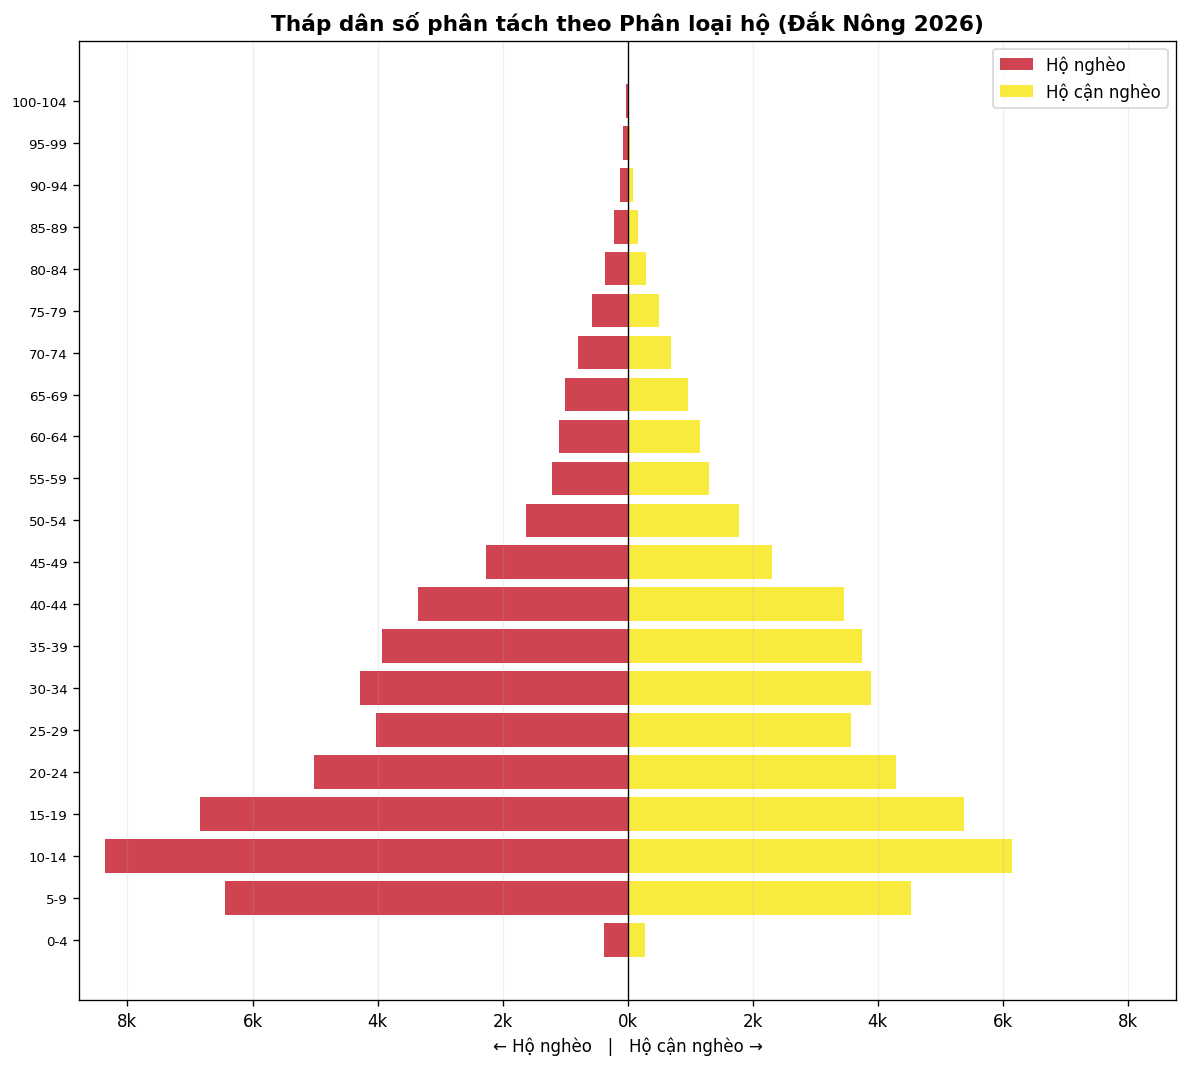

In [45]:
fig, ax = plt.subplots(figsize=(10, 9))
y  = np.arange(len(lbl_age))
mv = max(pyr_n.max(), pyr_c.max()) * 1.05
ax.barh(y, -pyr_n.values, color=CLR["ngheo"], alpha=0.85, label="Hộ nghèo")
ax.barh(y,  pyr_c.values, color=CLR["can"],   alpha=0.85, label="Hộ cận nghèo")
ax.set_yticks(y); ax.set_yticklabels(lbl_age, fontsize=8)
ax.set_xlim(-mv, mv)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{abs(x)/1000:.0f}k"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("← Hộ nghèo   |   Hộ cận nghèo →")
ax.set_title("Tháp dân số phân tách theo Phân loại hộ (Đắk Nông 2026)", fontweight="bold")
ax.legend(fontsize=10); ax.grid(axis="x", alpha=0.2)
plt.tight_layout(); plt.show()


### Nhận xét
**Lưu ý về đơn vị phân tích:** Tháp dân số này sử dụng đơn vị **nhân khẩu**. Vì vậy, biểu đồ phản ánh số lượng cá nhân theo nhóm tuổi trong các hộ nghèo/cận nghèo, không trực tiếp phản ánh số trẻ em trung bình trên mỗi hộ.

- Tháp dân số của cả hai nhóm có dạng đáy rộng và đỉnh hẹp, phản ánh cơ cấu nhân khẩu trẻ với tỷ trọng lớn ở nhóm trẻ em và thanh thiếu niên.
- Nhóm tuổi **10-14 tuổi** là nhóm đông nhất ở cả hai loại hộ, tiếp theo là các nhóm **5-9 tuổi** và **15-19 tuổi**.
- Trong hầu hết các nhóm tuổi từ **5-24 tuổi**, số nhân khẩu thuộc hộ nghèo cao hơn hộ cận nghèo.
- Từ nhóm tuổi **40-64 tuổi**, quy mô nhân khẩu giữa hai nhóm dần cân bằng, một số nhóm tuổi hộ cận nghèo nhỉnh hơn.
- Số lượng nhân khẩu giảm nhanh từ sau tuổi 65 và rất thấp ở các nhóm tuổi trên 85.

### Insight
- Nhân khẩu thuộc hộ nghèo tập trung nhiều hơn ở nhóm tuổi trẻ, đặc biệt nhóm tuổi học sinh **5-19 tuổi**.
- Chênh lệch quy mô giữa hai nhóm tập trung chủ yếu ở các nhóm tuổi học sinh, gợi ý cần quan tâm đến giáo dục và an sinh trẻ em trong nhóm hộ nghèo.
- Nhân khẩu thuộc hộ cận nghèo có xu hướng nhỉnh hơn ở một số nhóm tuổi lao động trung niên, nhưng cần phân tích cấp hộ để kết luận về lợi thế lao động của mỗi hộ.
- Các nhóm tuổi rất cao có số lượng nhỏ nên chỉ nên xem là thông tin tham khảo, không phải xu hướng chính.


#### 3.2. Mối liên hệ Tuổi chủ hộ - Quy mô nhân khẩu
**Mục tiêu:** Khám phá xem sự kết hợp giữa tuổi chủ hộ và quy mô nhân khẩu **có liên hệ** với tỷ lệ hộ nghèo hay không.
- Độ tuổi của chủ hộ tương quan thế nào với quy mô nhân khẩu?
- Nhóm chủ hộ trẻ/già kết hợp với quy mô hộ lớn có tỷ lệ hộ nghèo cao hơn các nhóm khác không?


#### Tuổi chủ hộ tương quan thế nào với quy mô nhân khẩu? 

In [46]:
from scipy.stats import pearsonr, spearmanr

chu_sc = df[df["QUANHE_CHUHO"]=="Chủ hộ"].dropna(subset=["TUOI","NHAN_KHAU"]).copy()

x_all = chu_sc["TUOI"].values
y_all = chu_sc["NHAN_KHAU"].values.astype(float)
r_p, p_p = pearsonr(x_all, y_all)
r_s, p_s = spearmanr(x_all, y_all)
coef      = np.polyfit(x_all, y_all, 1)

print("Tương quan Tuổi chủ hộ – Nhân khẩu:")
print(f"  Pearson r    = {r_p:.4f}  (p={p_p:.2e})")
print(f"  Spearman rho = {r_s:.4f}  (p={p_s:.2e})")
print(f"  Hồi quy:  NHAN_KHAU = {coef[0]:.4f} × TUOI + {coef[1]:.2f}")
print()
# Nhân khẩu TB theo nhóm tuổi chủ hộ
chu_sc["NHOM_T"] = pd.cut(chu_sc["TUOI"],
    bins=[0,30,40,50,60,70,110],
    labels=["<30","30-39","40-49","50-59","60-69","70+"])
nk = (chu_sc.groupby(["NHOM_T","PHAN_LOAI_HO"])["NHAN_KHAU"]
      .agg(N="count", TB_NK="mean").round(2).unstack())
print("Nhân khẩu TB theo nhóm tuổi chủ hộ & phân loại:")
print(nk.to_string())


Tương quan Tuổi chủ hộ – Nhân khẩu:
  Pearson r    = -0.0249  (p=4.31e-04)
  Spearman rho = -0.0868  (p=7.84e-35)
  Hồi quy:  NHAN_KHAU = -0.0130 × TUOI + 5.49

Nhân khẩu TB theo nhóm tuổi chủ hộ & phân loại:
                        N                 TB_NK         
PHAN_LOAI_HO Hộ cận nghèo Hộ nghèo Hộ cận nghèo Hộ nghèo
NHOM_T                                                  
<30                   387      550         3.88     4.81
30-39                2729     3146         4.58     4.92
40-49                2873     2833         4.98     5.43
50-59                1704     1591         5.22     5.72
60-69                1152     1149         4.30     4.66
70+                   837     1078         3.57     3.83


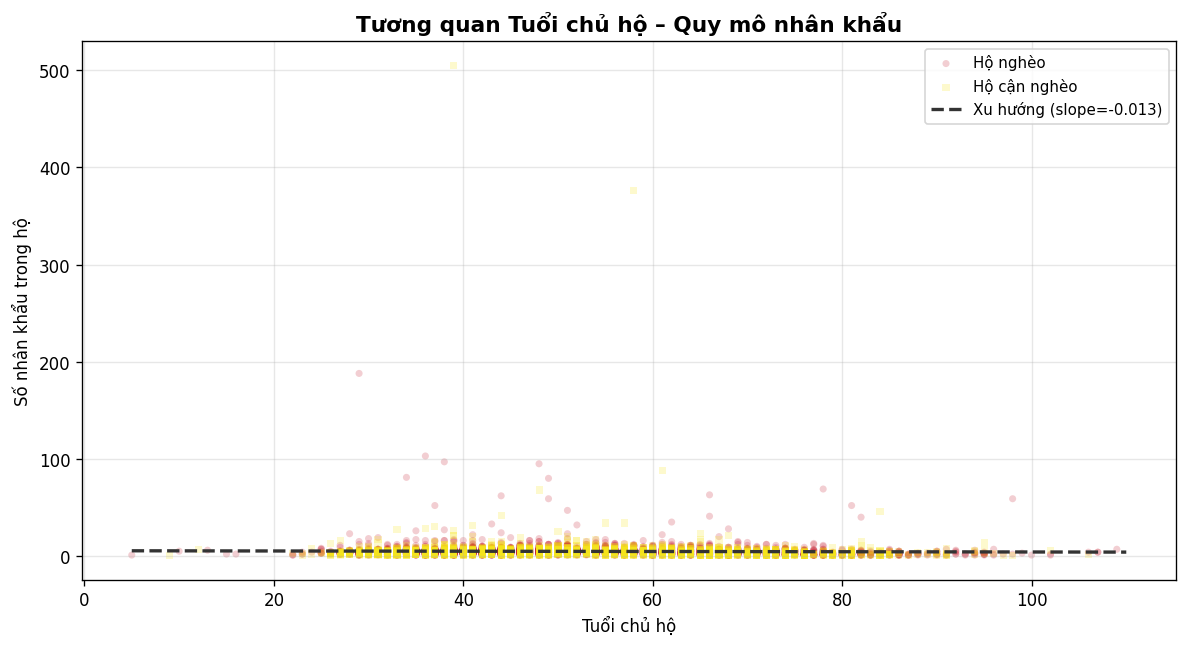

In [47]:
sample = chu_sc.sample(min(8000, len(chu_sc)), random_state=42)

fig, ax = plt.subplots(figsize=(10, 5.5))
for label, c, m in [("Hộ nghèo",CLR["ngheo"],"o"),("Hộ cận nghèo",CLR["can"],"s")]:
    s = sample[sample["PHAN_LOAI_HO"]==label]
    ax.scatter(s["TUOI"], s["NHAN_KHAU"], c=c, alpha=0.22, s=18,
               marker=m, label=label, edgecolors="none")
xline = np.linspace(x_all.min(), x_all.max(), 200)
ax.plot(xline, np.polyval(coef, xline), color="#333", lw=2, ls="--",
        label=f"Xu hướng (slope={coef[0]:.3f})")
ax.set_xlabel("Tuổi chủ hộ"); ax.set_ylabel("Số nhân khẩu trong hộ")
ax.set_title("Tương quan Tuổi chủ hộ – Quy mô nhân khẩu", fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### Nhận xét
- Các điểm dữ liệu tập trung dày ở vùng tuổi chủ hộ từ khoảng **20-80 tuổi** và quy mô hộ dưới **20 nhân khẩu**, cho thấy đây là cấu trúc phổ biến của phần lớn hộ nghèo và hộ cận nghèo trong tập dữ liệu.
- Đường xu hướng có độ dốc âm rất nhỏ, gần như nằm ngang, phù hợp với tương quan Pearson/Spearman thấp; tuổi chủ hộ hầu như không liên hệ mạnh với quy mô nhân khẩu hộ.
- Hộ nghèo và hộ cận nghèo phân bố tương đối giống nhau trên biểu đồ, không hình thành các cụm tách biệt rõ theo tuổi chủ hộ.
- Nếu biểu đồ được vẽ từ dữ liệu trước khi sửa feature engineering, các điểm có quy mô nhân khẩu hàng trăm người phản ánh lỗi gom hộ/trùng mã hộ và không nên dùng để diễn giải. Các outlier này đã được xử lý trong bảng `household_featured.xlsx` sau khi tạo lại `HOUSEHOLD_ID`.

### Insight
- Quy mô hộ gia đình không phụ thuộc nhiều vào tuổi chủ hộ; các hộ đông người và ít người đều xuất hiện ở nhiều nhóm tuổi.
- Sự khác biệt giữa hộ nghèo và hộ cận nghèo có thể liên quan nhiều hơn đến địa bàn, dân tộc, cơ cấu lao động hoặc điều kiện sinh kế hơn là riêng tuổi chủ hộ.
- Trước khi sử dụng biến `NHAN_KHAU` cho phân tích sâu, cần dùng phiên bản đã được xử lý ở cấp hộ để tránh ảnh hưởng của lỗi gom hộ.


#### Tổ hợp Tuổi chủ hộ × Nhân khẩu nào có tỉ lệ Hộ nghèo cao nhất? 

In [48]:
chu_sc["NHOM_NK"] = pd.cut(chu_sc["NHAN_KHAU"].astype(float),
    bins=[0,2,4,6,8,50], labels=["1-2","3-4","5-6","7-8","9+"])

pivot_pct = chu_sc.pivot_table(index="NHOM_T", columns="NHOM_NK",
    values="PHAN_LOAI_HO", aggfunc=lambda x: (x=="Hộ nghèo").mean()*100)
pivot_cnt = chu_sc.pivot_table(index="NHOM_T", columns="NHOM_NK",
    aggfunc="size", fill_value=0)

print("% Hộ nghèo theo Nhóm tuổi chủ hộ × Nhóm nhân khẩu:")
print(pivot_pct.round(1).to_string())
print()
print("Số lượng chủ hộ tương ứng:")
print(pivot_cnt.to_string())
max_idx = pivot_pct.stack().idxmax()
max_val = pivot_pct.stack().max()
print(f"\n⚠️  Ô nguy cơ cao nhất: Tuổi {max_idx[0]}, Nhân khẩu {max_idx[1]} → {max_val:.1f}% Hộ nghèo")


% Hộ nghèo theo Nhóm tuổi chủ hộ × Nhóm nhân khẩu:
NHOM_NK   1-2   3-4   5-6   7-8    9+
NHOM_T                               
<30      59.7  52.2  71.3  64.1  70.0
30-39    62.0  43.5  59.7  68.8  64.4
40-49    57.2  45.0  46.1  59.6  67.3
50-59    52.7  43.6  44.8  55.0  59.5
60-69    51.4  48.1  45.2  54.6  58.0
70+      59.2  51.2  53.3  62.4  48.4

Số lượng chủ hộ tương ứng:
NHOM_NK  1-2   3-4   5-6  7-8   9+
NHOM_T                            
<30      154   510   202   39   30
30-39    702  2634  1935  416  177
40-49    582  2113  2011  663  324
50-59    457  1118   975  413  328
60-69    675   752   471  218  181
70+      979   463   285  117   64

⚠️  Ô nguy cơ cao nhất: Tuổi <30, Nhân khẩu 5-6 → 71.3% Hộ nghèo


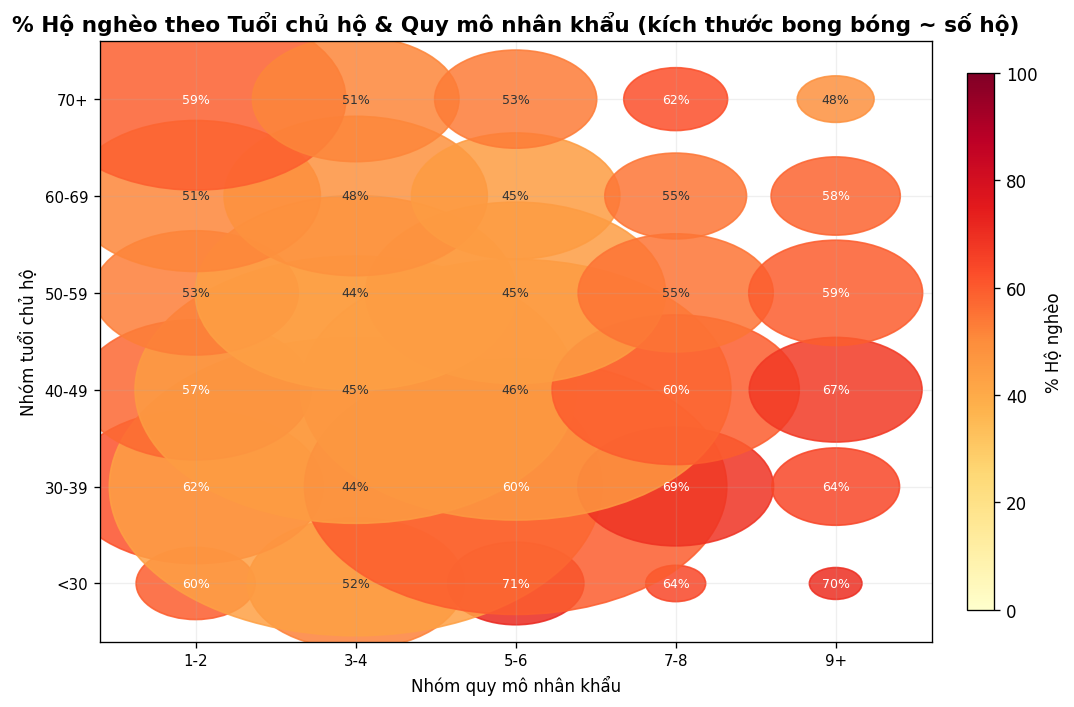

In [49]:
fig, ax = plt.subplots(figsize=(9, 6))
for yi in range(len(pivot_pct.index)):
    for xi in range(len(pivot_pct.columns)):
        val = pivot_pct.iloc[yi, xi]
        cnt = pivot_cnt.iloc[yi, xi]
        if np.isnan(val) or cnt == 0: continue
        circle = plt.Circle((xi, yi), np.sqrt(cnt)*3/100,
                             color=plt.cm.YlOrRd(val/100), alpha=0.85)
        ax.add_patch(circle)
        ax.text(xi, yi, f"{val:.0f}%", ha="center", va="center",
                fontsize=7.5, fontweight="500",
                color="white" if val > 55 else "#333")
ax.set_xlim(-0.6, len(pivot_pct.columns)-0.4)
ax.set_ylim(-0.6, len(pivot_pct.index)-0.4)
ax.set_xticks(range(len(pivot_pct.columns))); ax.set_xticklabels(pivot_pct.columns, fontsize=9)
ax.set_yticks(range(len(pivot_pct.index)));   ax.set_yticklabels(pivot_pct.index, fontsize=9)
ax.set_xlabel("Nhóm quy mô nhân khẩu"); ax.set_ylabel("Nhóm tuổi chủ hộ")
ax.set_title("% Hộ nghèo theo Tuổi chủ hộ & Quy mô nhân khẩu (kích thước bong bóng ~ số hộ)", fontweight="bold")
sm = plt.cm.ScalarMappable(cmap="YlOrRd", norm=plt.Normalize(0,100))
plt.colorbar(sm, ax=ax, label="% Hộ nghèo", fraction=0.03, pad=0.04)
ax.grid(True, alpha=0.2)
plt.tight_layout(); plt.show()


#### Nhận xét
- Tỷ lệ hộ nghèo có sự khác biệt theo quy mô nhân khẩu rõ hơn so với tuổi chủ hộ.
- Các hộ có quy mô lớn từ **7 nhân khẩu trở lên** thường ghi nhận tỷ lệ hộ nghèo cao hơn các hộ có quy mô trung bình.
- Nhóm chủ hộ **dưới 30 tuổi** có tỷ lệ hộ nghèo cao khi quy mô hộ đạt **5-6 nhân khẩu** hoặc **từ 9 nhân khẩu trở lên**.
- Ở các nhóm tuổi lao động từ **30-59 tuổi**, tỷ lệ hộ nghèo thấp hơn thường tập trung ở các hộ có quy mô **3-6 nhân khẩu**.
- Các bong bóng lớn nhất tập trung ở nhóm chủ hộ từ **30-69 tuổi** với quy mô hộ **3-6 nhân khẩu**, cho thấy đây là cấu trúc hộ phổ biến trong tập dữ liệu.

#### Insight
- Dữ liệu gợi ý quy mô nhân khẩu có liên hệ với tỷ lệ hộ nghèo rõ hơn tuổi chủ hộ.
- Các hộ quy mô lớn có xu hướng nghèo cao hơn, có thể do áp lực phụ thuộc và chi tiêu lớn hơn; tuy nhiên đây vẫn là quan hệ quan sát, chưa đủ cơ sở kết luận cơ chế nhân quả.
- Nhóm chủ hộ trẻ (<30 tuổi) kết hợp với quy mô hộ lớn là nhóm có tỷ lệ nghèo quan sát cao, nên có thể xem là nhóm ưu tiên để phân tích sâu hơn về sinh kế, việc làm và phụ thuộc trẻ em.
- Các hộ quy mô trung bình từ **3-6 nhân khẩu** có tỷ lệ nghèo thấp hơn tương đối ổn định ở nhiều nhóm tuổi, gợi ý cấu trúc hộ này cân bằng hơn giữa số người lao động và số người phụ thuộc.
- Không nên dùng các cụm từ như “bẫy nghèo kép” hoặc “bẫy nghèo trẻ” như kết luận chắc chắn. Có thể xem đây là **giả thuyết phân tích** cần kiểm chứng thêm bằng dữ liệu theo thời gian hoặc các biến về thu nhập, việc làm, học vấn và tài sản.


### 3.3. Tương quan Đa chiều Không gian & Văn hóa
**Mục tiêu:** Tìm hiểu cơ cấu tuổi và tình trạng nghèo/cận nghèo có **phân hóa theo địa bàn và dân tộc** hay không.
- Cơ cấu độ tuổi của các nhóm dân tộc tại chỗ và dân tộc di cư có sự phân hóa thế nào?
- Tỷ lệ nhân khẩu U50+ thuộc hộ nghèo khác nhau thế nào theo xã/huyện?


In [4]:
# ── Giá trị ──
TOP_DT  = ["Dao", "M'Nông", "Kinh", "H'Mông", "Ê-đê", "Tày"]
df_dt   = df[df["DAN_TOC"].isin(TOP_DT)].dropna(subset=["TUOI"])
order_dt = (df_dt.groupby("DAN_TOC")["TUOI"].median()
                 .sort_values(ascending=False).index.tolist())

stats_dt = (df_dt.groupby(["DAN_TOC","PHAN_LOAI_HO"])["TUOI"]
            .agg(N="count", TB="mean", Median="median",
                 SD="std", U50_pct=lambda x: (x>=50).mean()*100)
            .round(1))
stats_dt.columns = ["N","Tuổi TB","Trung vị","SD","% U50+"]
print("Thống kê tuổi & % U50+ theo Dân tộc & Phân loại:")
print(stats_dt.to_string())
print()
u50_agg = (df_dt[df_dt["PHAN_LOAI_HO"]=="Hộ nghèo"]
           .groupby("DAN_TOC")["TUOI"]
           .apply(lambda x: (x>=50).mean()*100).round(1)
           .sort_values(ascending=False))
print("Tỉ lệ U50+ trong nhóm Hộ nghèo theo dân tộc:")
print(u50_agg.to_string())

Thống kê tuổi & % U50+ theo Dân tộc & Phân loại:
                          N  Tuổi TB  Trung vị    SD  % U50+
DAN_TOC PHAN_LOAI_HO                                        
Dao     Hộ cận nghèo   4194     26.7      22.0  17.0    11.5
        Hộ nghèo      19149     24.6      20.0  16.4     8.5
H'Mông  Hộ cận nghèo   2048     31.9      30.0  18.6    16.9
        Hộ nghèo       2179     31.6      29.0  19.6    17.3
Kinh    Hộ cận nghèo  14615     32.6      30.0  19.7    19.8
        Hộ nghèo      10869     32.9      30.0  20.9    20.8
M'Nông  Hộ cận nghèo  10093     27.5      24.0  17.9    12.1
        Hộ nghèo       9379     27.5      23.0  18.6    12.8
Tày     Hộ cận nghèo   1814     31.9      30.0  19.0    17.4
        Hộ nghèo       1829     31.2      29.0  19.5    16.5
Ê-đê    Hộ cận nghèo   2314     30.4      28.5  17.9    14.0
        Hộ nghèo       2270     31.0      27.0  20.9    16.9

Tỉ lệ U50+ trong nhóm Hộ nghèo theo dân tộc:
DAN_TOC
Kinh      20.8
H'Mông    17.3
Ê-đê      16.

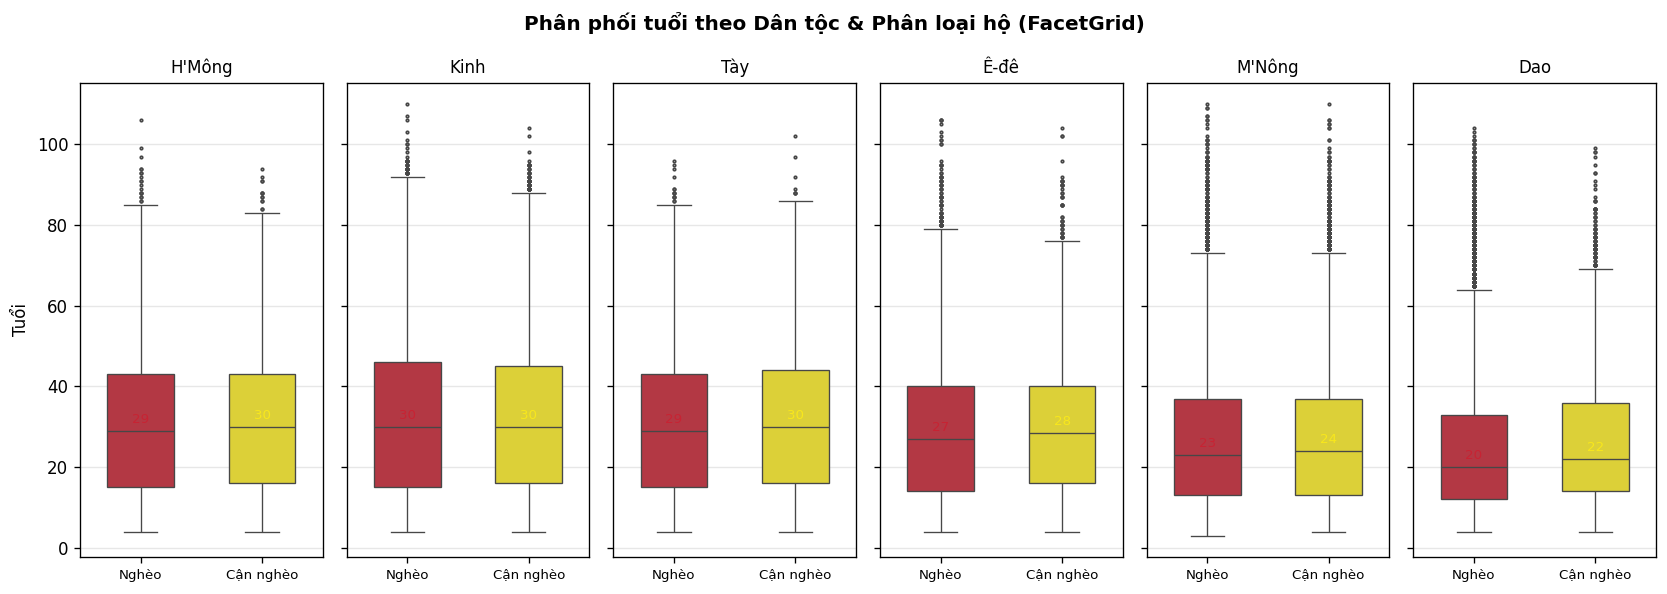

In [5]:
fig, axes = plt.subplots(1, len(order_dt), figsize=(14, 5), sharey=True)
fig.suptitle("Phân phối tuổi theo Dân tộc & Phân loại hộ (FacetGrid)", fontweight="bold")
for ax_i, dt in zip(axes, order_dt):
    sub = df_dt[df_dt["DAN_TOC"]==dt]
    sns.boxplot(data=sub, x="PHAN_LOAI_HO", y="TUOI",
                order=["Hộ nghèo","Hộ cận nghèo"],
                palette=[CLR["ngheo"], CLR["can"]],
                width=0.55, linewidth=0.8, fliersize=1.5, ax=ax_i)
    ax_i.set_title(dt, fontsize=10, fontweight="500")
    ax_i.set_xlabel(""); ax_i.set_xticklabels(["Nghèo","Cận nghèo"], fontsize=8)
    if ax_i != axes[0]: ax_i.set_ylabel("")
    for loai, xpos, c in [("Hộ nghèo",0,CLR["ngheo"]),("Hộ cận nghèo",1,CLR["can"])]:
        med = sub[sub["PHAN_LOAI_HO"]==loai]["TUOI"].median()
        if not np.isnan(med):
            ax_i.text(xpos, med+2, f"{med:.0f}", ha="center", fontsize=8, color=c, fontweight="500")
    ax_i.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Tuổi")
plt.tight_layout(); plt.show()


#### Nhận xét
- Cơ cấu tuổi giữa hộ nghèo và hộ cận nghèo trong cùng một dân tộc khá tương đồng, với trung vị tuổi của hộ cận nghèo thường bằng hoặc nhỉnh hơn hộ nghèo.
- Dân tộc Kinh, H'Mông và Tày có trung vị tuổi cao hơn, cho thấy cơ cấu nhân khẩu nghèo/cận nghèo tương đối trưởng thành hơn.
- Dân tộc M'Nông và đặc biệt là Dao có trung vị tuổi thấp hơn, phản ánh tỷ trọng trẻ em và thanh thiếu niên cao hơn trong các hộ nghèo/cận nghèo.
- Phân phối tuổi của người Kinh trải rộng hơn các dân tộc khác, trong khi Dao và M'Nông tập trung nhiều ở nhóm tuổi trẻ.
- Tất cả các dân tộc đều xuất hiện nhóm người cao tuổi trong hộ nghèo và cận nghèo, nhưng quy mô không lớn.

#### Insight
- Dữ liệu gợi ý nghèo/cận nghèo ở các nhóm Dao và M'Nông gắn với cơ cấu nhân khẩu trẻ hơn, qua đó đặt ra nhu cầu phân tích thêm về phụ thuộc trẻ em, giáo dục và sinh kế hộ.
- Nhóm Kinh, H'Mông và Tày có tỷ trọng người trưởng thành/trung niên lớn hơn; vấn đề nghèo ở các nhóm này có thể liên quan nhiều hơn đến việc làm, thu nhập và chất lượng sinh kế, nhưng cần thêm biến để kiểm chứng.
- Sự khác biệt tuổi giữa hộ nghèo và hộ cận nghèo trong cùng dân tộc không lớn, nên không nên xem tuổi là yếu tố giải thích chính nếu chưa kiểm soát địa bàn và dân tộc.
- Sự tồn tại của nhóm người rất cao tuổi trong các hộ nghèo gợi ý nhu cầu chính sách an sinh và chăm sóc người cao tuổi.


#### Tỷ lệ nhân khẩu U50+ thuộc hộ nghèo khác nhau thế nào theo xã/huyện?


In [6]:
# ── Giá trị ──
top_xa  = df.groupby("XA").size().nlargest(24).index
df_xa   = df[df["XA"].isin(top_xa)].dropna(subset=["TUOI"]).copy()
df_xa["U50_NGHEO"] = ((df_xa["TUOI"]>=50) & (df_xa["PHAN_LOAI_HO"]=="Hộ nghèo")).astype(int)
heat_df = (df_xa.pivot_table(index="XA", columns="HUYEN",
                              values="U50_NGHEO", aggfunc="mean") * 100)
heat_df = heat_df.dropna(how="all",axis=1).dropna(how="all",axis=0)
heat_df = heat_df.loc[heat_df.mean(axis=1).sort_values(ascending=False).index]

heat_mean = heat_df.mean(axis=1).sort_values(ascending=False)
print("Tỉ lệ U50+ là Hộ nghèo theo Xã (Top 24 xã, sắp xếp giảm dần):")
print(heat_mean.round(1).to_string())
print(f"\nXã cao nhất: {heat_mean.idxmax()} ({heat_mean.max():.1f}%)")
print(f"Xã thấp nhất: {heat_mean.idxmin()} ({heat_mean.min():.1f}%)")
print(f"Trung bình 24 xã: {heat_mean.mean():.1f}%")


Tỉ lệ U50+ là Hộ nghèo theo Xã (Top 24 xã, sắp xếp giảm dần):
XA
QUẢNG TÂN      11.0
QUẢNG TÂM      10.7
ĐẮK BÚK SO     10.3
QUẢNG SƠN      10.1
NAM DONG       10.0
ĐẮK HA          9.8
QUẢNG HÒA       9.7
ĐẮK SOM         9.4
TRƯỜNG XUÂN     9.1
QUẢNG TRỰC      9.1
ĐẮK WIL         8.6
ĐẮK PLAO        8.6
ĐẮK R'MĂNG      7.7
CƯ K'NIA        6.4
TÂM THẮNG       6.1
EAT'LING        5.8
ĐẮK GẰN         4.2
NAM ĐÀ          4.1
QUẢNG KHÊ       4.0
ĐĂK NANG        2.6
ĐẮK MÔL         2.6
QUẢNG PHÚ       2.1
NÂM NUNG        1.1
ĐẮ R'TÍH        0.0

Xã cao nhất: QUẢNG TÂN (11.0%)
Xã thấp nhất: ĐẮ R'TÍH (0.0%)
Trung bình 24 xã: 6.8%


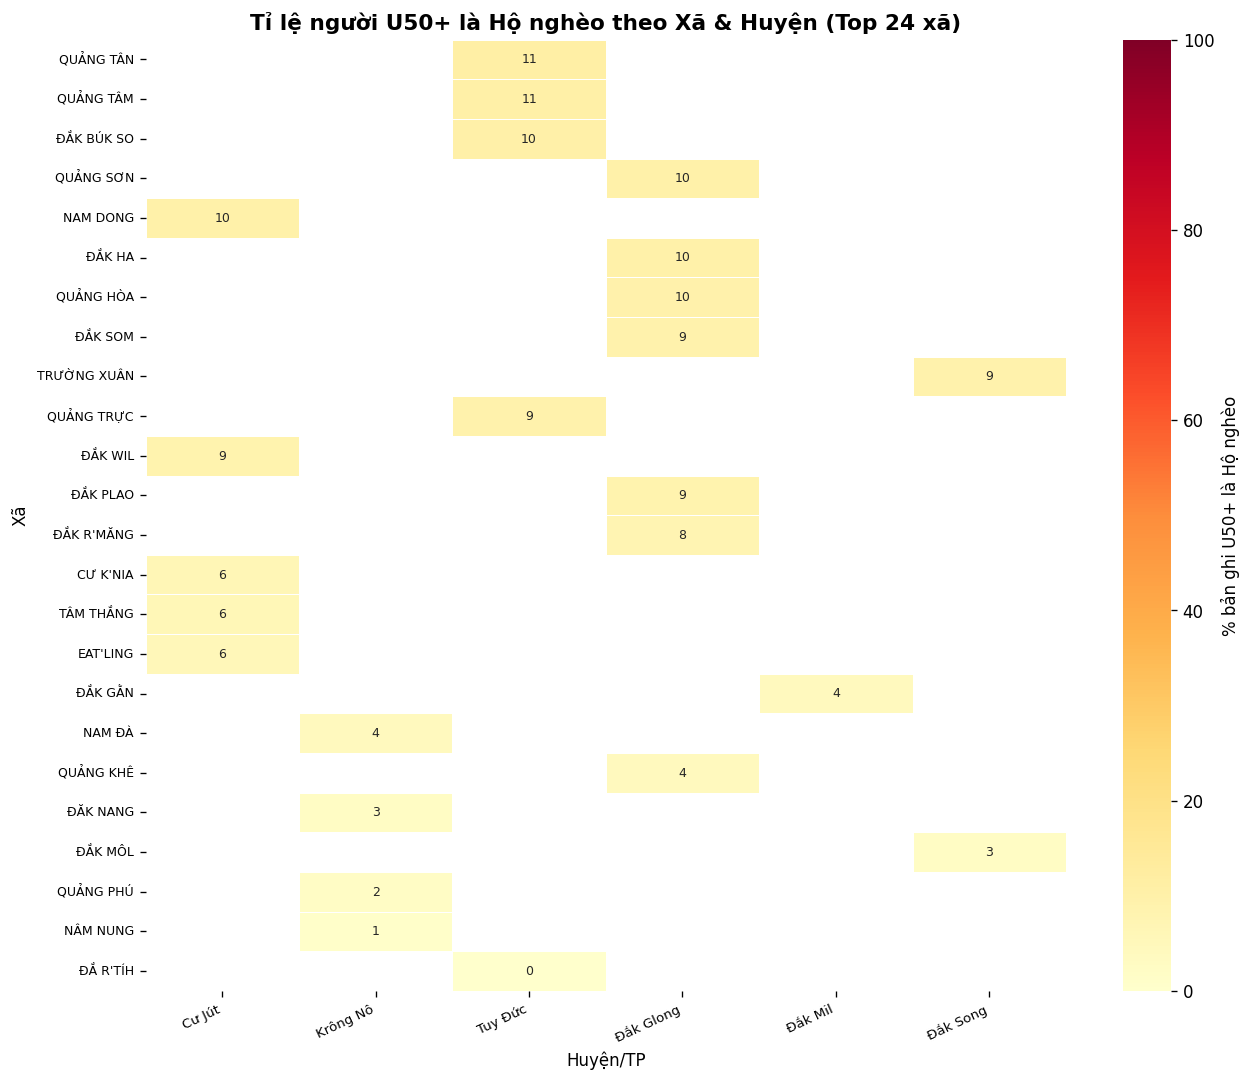

In [7]:
fig, ax = plt.subplots(figsize=(11, max(6, len(heat_df)*0.38)))
sns.heatmap(heat_df, cmap="YlOrRd", annot=True, fmt=".0f",
            annot_kws={"size":7.5}, linewidths=0.4,
            cbar_kws={"label":"% bản ghi U50+ là Hộ nghèo"},
            ax=ax, vmin=0, vmax=100)
ax.set_title("Tỉ lệ người U50+ là Hộ nghèo theo Xã & Huyện (Top 24 xã)", fontweight="bold")
ax.set_xlabel("Huyện/TP"); ax.set_ylabel("Xã")
ax.set_xticklabels(
    [l.get_text().replace("Huyện ","").replace("Thành phố ","TP ") for l in ax.get_xticklabels()],
    rotation=25, ha="right", fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=7.5)
plt.tight_layout(); plt.show()


#### Nhận xét
- Tỷ lệ nhân khẩu U50+ thuộc hộ nghèo tại các xã dao động từ 0,0% đến 11,0%, với mức trung bình của 24 xã là 6,8%.
- Các xã có tỷ lệ cao nhất gồm Quảng Tân, Quảng Tâm, Đắk Búk So, Quảng Sơn và Nam Dong.
- Huyện Tuy Đức và Đắk Glong tập trung nhiều xã có tỷ lệ cao, trong khi các xã thuộc huyện Krông Nô chủ yếu nằm ở nhóm thấp.
- Đắk R'Tíh ghi nhận tỷ lệ 0,0%, tức không ghi nhận nhân khẩu từ 50 tuổi trở lên thuộc hộ nghèo trong tập dữ liệu phân tích.
- Mặc dù giá trị tuyệt đối không cao, sự chênh lệch giữa các xã cho thấy cơ cấu tuổi của nhóm nghèo có khác biệt theo địa bàn.

#### Insight
- Tại Tuy Đức và Đắk Glong, tỷ trọng người từ 50 tuổi trở lên trong nhóm hộ nghèo cao hơn mặt bằng của các xã được chọn, gợi ý cần phân tích thêm yếu tố tuổi và an sinh ở các địa bàn này.
- Krông Nô có tỷ lệ thấp hơn trong bảng quan sát, nhưng cần kiểm tra thêm bằng dữ liệu cấp hộ và quy mô mẫu trước khi xem đây là đặc điểm ổn định.
- Việc nhiều xã của cùng một huyện cùng xuất hiện ở nhóm tỷ lệ cao gợi ý khả năng có yếu tố địa bàn chung, nhưng cần thêm biến kinh tế - xã hội, hạ tầng và sinh kế để giải thích.
- Sự hiện diện của người cao tuổi trong nhóm nghèo làm nổi bật nhu cầu chính sách an sinh, chăm sóc sức khỏe và hỗ trợ sinh kế phù hợp với khả năng lao động.


In [15]:
output_file = (
    r"C:\NguyenHoangThanhTam\data\clean"
    r"\Chuan_hoa_Toan_Tinh_EDA.xlsx"
)

df.to_excel(
    output_file,
    sheet_name="Du_lieu_chuan_hoa",
    index=False
)

print("Đã lưu:", output_file)

Đã lưu: C:\NguyenHoangThanhTam\data\clean\Chuan_hoa_Toan_Tinh.xlsx
